# PulmoSight 10 — v2 Evaluation: Did We Fix Overfitting, Fragility and Shortcuts?

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

In [3]:
class SqueezeExcite(nn.Module):
    """Channel attention: learn which feature maps matter for this image."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, channels // reduction, 1),
                                nn.SiLU(), nn.Conv2d(channels // reduction, channels, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, stride=1, act=True):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout),
                         nn.SiLU() if act else nn.Identity())


class ResidualSEBlock(nn.Module):
    """3x3 conv -> 3x3 conv -> squeeze-excite, plus a (projected) skip connection."""
    def __init__(self, cin, cout, stride=1, drop_path=0.0):
        super().__init__()
        self.body = nn.Sequential(ConvBNAct(cin, cout, 3, stride), ConvBNAct(cout, cout, 3, act=False),
                                  SqueezeExcite(cout))
        self.skip = (nn.Identity() if stride == 1 and cin == cout else
                     nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(),
                                   ConvBNAct(cin, cout, 1, act=False)))
        self.drop_path = drop_path
        self.act = nn.SiLU()

    def forward(self, x):
        out = self.body(x)
        if self.training and self.drop_path > 0:   # stochastic depth
            keep = torch.rand(out.size(0), 1, 1, 1, device=out.device) >= self.drop_path
            out = out * keep / (1 - self.drop_path)
        return self.act(out + self.skip(x))


class PulmoNet(nn.Module):
    """Custom CNN for 1-channel 512x512 chest X-rays, trained from scratch.

    512 -> stem (128) -> stage1 (128) -> stage2 (64) -> stage3 (32) -> stage4 (16) -> GAP -> FC
    """
    def __init__(self, widths=(48, 96, 160, 256), depths=(2, 2, 3, 2), num_classes=2, drop=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(ConvBNAct(1, 32, 5, 2), ConvBNAct(32, 32, 3), ConvBNAct(32, widths[0], 3, 2))
        total, idx, cin, stages = sum(depths), 0, widths[0], []
        for i, (w, d) in enumerate(zip(widths, depths)):
            blocks = []
            for j in range(d):
                stride = 2 if (j == 0 and i > 0) else 1
                blocks.append(ResidualSEBlock(cin, w, stride, drop_path * idx / max(total - 1, 1)))
                cin, idx = w, idx + 1
            stages.append(nn.Sequential(*blocks))
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.head_conv = ConvBNAct(cin, 512, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(512, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def features(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head_conv(x)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [4]:
from torchvision import models

def build_efficientnet_b0(pretrained=True, drop=0.3, stochastic_depth=0.2):
    """ImageNet EfficientNet-B0 adapted to 1-channel X-rays (RGB stem filters summed)."""
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights, stochastic_depth_prob=stochastic_depth)
    stem = model.features[0][0]
    gray = nn.Conv2d(1, stem.out_channels, stem.kernel_size, stem.stride, stem.padding, bias=False)
    with torch.no_grad():
        gray.weight.copy_(stem.weight.sum(dim=1, keepdim=True))
    model.features[0][0] = gray
    model.classifier = nn.Sequential(nn.Dropout(drop), nn.Linear(1280, 2))
    return model

In [5]:
full = pd.read_csv(ROOT / "splits" / "splits.csv")
crop = pd.read_csv(ROOT / "splits" / "splits_lungcrop.csv").set_index("orig_path").loc[full.path].reset_index()
assert (crop.orig_path.values == full.path.values).all()
DATA = {"full": full, "crop": crop}

def frame(kind, split):
    return DATA[kind][DATA[kind].split == split].reset_index(drop=True)

def load(arch, run, **kw):
    ck = torch.load(ROOT / "models" / run / "best.pth", map_location="cpu", weights_only=False)
    kw = {**ck.get("model_kwargs", {}), **kw}
    m = PulmoNet(**kw) if arch == "pulmonet" else build_efficientnet_b0(pretrained=False, **kw)
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE, memory_format=torch.channels_last).eval()

SPECS = {  # name: (arch, run dir, input)
    "PulmoNet v1":             ("pulmonet", "pulmonet", "full"),
    "EfficientNet v1":         ("efficientnet_b0", "efficientnet_b0", "full"),
    "PulmoNet v2":             ("pulmonet", "pulmonet_v2", "crop"),
    "EfficientNet v2 (s42)":   ("efficientnet_b0", "efficientnet_b0_v2/seed42", "crop"),
    "EfficientNet v2 (s7)":    ("efficientnet_b0", "efficientnet_b0_v2/seed7", "crop"),
    "EfficientNet v2 (s2024)": ("efficientnet_b0", "efficientnet_b0_v2/seed2024", "crop"),
}
models_ = {n: load(a, r) for n, (a, r, _) in SPECS.items()}
INPUT = {n: k for n, (_, _, k) in SPECS.items()}
print("Loaded:", list(models_))

Loaded: ['PulmoNet v1', 'EfficientNet v1', 'PulmoNet v2', 'EfficientNet v2 (s42)', 'EfficientNet v2 (s7)', 'EfficientNet v2 (s2024)']


## 1. Score every model on train (clean), validation and test

In [6]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")

@torch.no_grad()
def logits_of(model, df, bs=64):
    model.eval(); out = []
    for x, _ in XrayLoader(df, bs):
        x = ((x.to(DEVICE).float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        with autocast():
            out.append(model(x).float().cpu())
    lg = torch.cat(out).numpy()
    return lg[:, 1] - lg[:, 0]          # logit margin; softmax P(TB) = sigmoid(margin)

from scipy.special import expit
margins = {}
for n, m in models_.items():
    t0 = time.time()
    margins[n] = {s: logits_of(m, frame(INPUT[n], s)) for s in ["train", "val", "test"]}
    print(f"{n:<24} scored in {time.time() - t0:.0f}s")
seed_names = [n for n in margins if n.startswith("EfficientNet v2 (s")]
ens = "EfficientNet v2 ensemble"
margins[ens] = {s: np.mean([margins[n][s] for n in seed_names], axis=0) for s in ["train", "val", "test"]}
INPUT[ens] = "crop"
Y = {s: frame("full", s).label.to_numpy() for s in ["train", "val", "test"]}
NAMES = list(margins)

PulmoNet v1              scored in 63s


EfficientNet v1          scored in 152s


PulmoNet v2              scored in 23s


EfficientNet v2 (s42)    scored in 40s


EfficientNet v2 (s7)     scored in 41s


EfficientNet v2 (s2024)  scored in 41s


## 2. Calibrate (temperature) and lock thresholds on validation

In [7]:
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, log_loss

def fit_T(m, y):
    nll = lambda T: log_loss(y, np.clip(expit(m / T), 1e-7, 1 - 1e-7))
    return minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x

T = {n: fit_T(margins[n]["val"], Y["val"]) for n in NAMES}
P = {n: {s: expit(margins[n][s] / T[n]) for s in ["train", "val", "test"]} for n in NAMES}

def thresholds(y, p, min_spec=0.95, min_sens=0.90):
    fpr, tpr, thr = roc_curve(y, p); thr = np.minimum(thr, 1.0)
    spec = 1 - fpr
    return {"balanced": float(thr[np.argmax(tpr - fpr)]),
            "high_spec": float(thr[spec >= min_spec][np.argmax(tpr[spec >= min_spec])]),
            "screening": float(thr[tpr >= min_sens][np.argmax(spec[tpr >= min_sens])])}   # sensitivity >= 90% on val
TH = {n: thresholds(Y["val"], P[n]["val"]) for n in NAMES}
display(pd.DataFrame({n: {"temperature": T[n], **TH[n]} for n in NAMES}).T.round(3))

,temperature,balanced,high_spec,screening
PulmoNet v1,1.091,0.710,0.766,0.345
EfficientNet v1,1.226,0.510,0.784,0.351
PulmoNet v2,0.897,0.482,0.791,0.274
EfficientNet v2 (s42),0.976,0.436,0.603,0.217
EfficientNet v2 (s7),0.976,0.379,0.638,0.219
EfficientNet v2 (s2024),0.945,0.368,0.654,0.227
EfficientNet v2 ensemble,0.952,0.385,0.624,0.207


## 3. Test-set performance with 95% bootstrap confidence intervals

In [8]:
def metrics(y, p, t):
    pred = p >= t; tp = (pred & (y == 1)).sum(); tn = (~pred & (y == 0)).sum(); fp = (pred & (y == 0)).sum(); fn = (~pred & (y == 1)).sum()
    return {"AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p), "Accuracy": (tp + tn) / len(y),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "Brier": np.mean((p - y) ** 2)}

rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, len(Y["test"]), size=(500, len(Y["test"])))
def ci(y, p, t):
    pt = metrics(y, p, t); bs = pd.DataFrame([metrics(y[i], p[i], t) for i in BOOT])
    return {k: (v, bs[k].quantile(0.025), bs[k].quantile(0.975)) for k, v in pt.items()}

RES = {(op, n): ci(Y["test"], P[n]["test"], TH[n][op]) for op in ["balanced", "screening"] for n in NAMES}
fmt = lambda c: f"{c[0]:.3f} [{c[1]:.3f}–{c[2]:.3f}]"
for op, title in [("balanced", "balanced threshold (Youden)"), ("screening", "screening threshold (sensitivity ≥ 90% on validation)")]:
    print(f"\n=== TEST — {title} ===")
    display(pd.DataFrame({n: {k: fmt(v) for k, v in RES[(op, n)].items()} for n in NAMES}))


=== TEST — balanced threshold (Youden) ===


,PulmoNet v1,EfficientNet v1,PulmoNet v2,EfficientNet v2 (s42),EfficientNet v2 (s7),EfficientNet v2 (s2024),EfficientNet v2 ensemble
AUROC,0.906 [0.892–0.920],0.933 [0.922–0.945],0.895 [0.879–0.911],0.894 [0.879–0.910],0.892 [0.877–0.907],0.895 [0.880–0.911],0.895 [0.881–0.911]
AUPRC,0.920 [0.907–0.933],0.937 [0.924–0.951],0.906 [0.890–0.921],0.905 [0.889–0.921],0.902 [0.886–0.918],0.905 [0.890–0.922],0.906 [0.891–0.922]
Accuracy,0.835 [0.817–0.853],0.854 [0.837–0.871],0.816 [0.798–0.835],0.816 [0.796–0.835],0.818 [0.800–0.837],0.820 [0.802–0.838],0.819 [0.801–0.838]
Sensitivity,0.741 [0.711–0.775],0.828 [0.804–0.854],0.776 [0.750–0.807],0.751 [0.723–0.781],0.796 [0.768–0.827],0.799 [0.773–0.828],0.785 [0.758–0.814]
Specificity,0.925 [0.905–0.940],0.878 [0.858–0.899],0.855 [0.831–0.879],0.878 [0.857–0.901],0.839 [0.814–0.864],0.840 [0.815–0.864],0.851 [0.828–0.877]
Brier,0.122 [0.111–0.132],0.102 [0.091–0.111],0.129 [0.118–0.140],0.133 [0.122–0.144],0.133 [0.123–0.143],0.131 [0.120–0.142],0.131 [0.121–0.142]



=== TEST — screening threshold (sensitivity ≥ 90% on validation) ===


,PulmoNet v1,EfficientNet v1,PulmoNet v2,EfficientNet v2 (s42),EfficientNet v2 (s7),EfficientNet v2 (s2024),EfficientNet v2 ensemble
AUROC,0.906 [0.892–0.920],0.933 [0.922–0.945],0.895 [0.879–0.911],0.894 [0.879–0.910],0.892 [0.877–0.907],0.895 [0.880–0.911],0.895 [0.881–0.911]
AUPRC,0.920 [0.907–0.933],0.937 [0.924–0.951],0.906 [0.890–0.921],0.905 [0.889–0.921],0.902 [0.886–0.918],0.905 [0.890–0.922],0.906 [0.891–0.922]
Accuracy,0.808 [0.790–0.827],0.844 [0.826–0.861],0.784 [0.765–0.804],0.794 [0.776–0.814],0.788 [0.771–0.808],0.792 [0.774–0.812],0.788 [0.769–0.808]
Sensitivity,0.867 [0.846–0.892],0.876 [0.853–0.899],0.876 [0.854–0.898],0.866 [0.843–0.891],0.877 [0.855–0.901],0.867 [0.843–0.891],0.877 [0.854–0.901]
Specificity,0.753 [0.723–0.778],0.813 [0.786–0.839],0.697 [0.666–0.730],0.725 [0.696–0.754],0.703 [0.676–0.734],0.721 [0.693–0.750],0.703 [0.676–0.736]
Brier,0.122 [0.111–0.132],0.102 [0.091–0.111],0.129 [0.118–0.140],0.133 [0.122–0.144],0.133 [0.123–0.143],0.131 [0.120–0.142],0.131 [0.121–0.142]


## 4. Overfitting: train vs validation vs test

,train AUROC (clean),val AUROC,test AUROC,train−test AUROC,val−test AUROC,test/train log-loss
PulmoNet v1,0.9758,0.9245,0.9058,0.0699,0.0187,1.7707
EfficientNet v1,0.9857,0.9389,0.9328,0.0529,0.0061,1.8867
PulmoNet v2,0.9533,0.9081,0.8953,0.0580,0.0128,1.4230
EfficientNet v2 (s42),0.9354,0.9087,0.8941,0.0414,0.0146,1.2371
EfficientNet v2 (s7),0.9342,0.9050,0.8918,0.0425,0.0132,1.2378
EfficientNet v2 (s2024),0.9360,0.9120,0.8947,0.0413,0.0173,1.2406
EfficientNet v2 ensemble,0.9370,0.9106,0.8954,0.0416,0.0152,1.2437


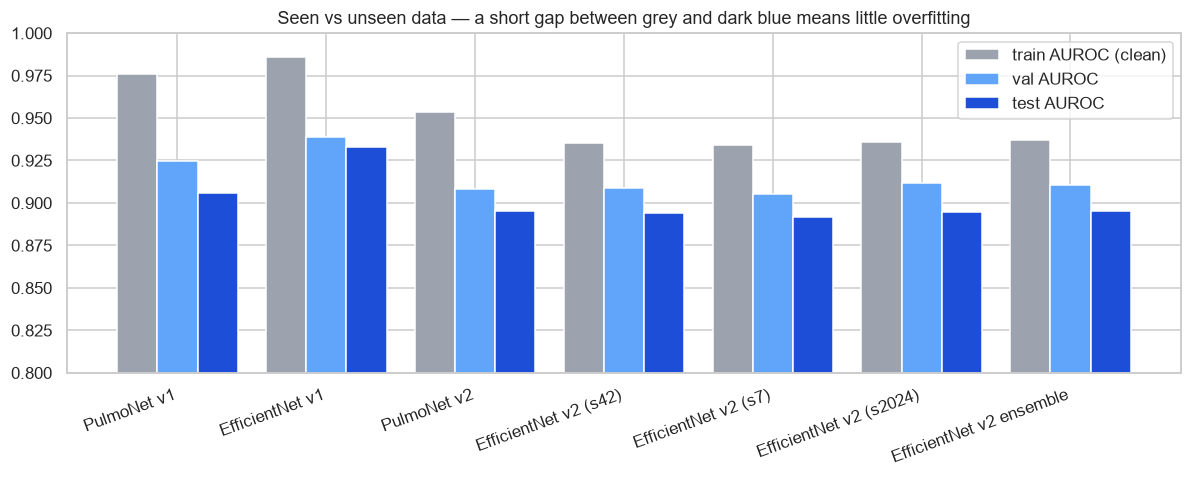

In [9]:
ov = pd.DataFrame({n: {"train AUROC (clean)": roc_auc_score(Y["train"], P[n]["train"]),
                       "val AUROC": roc_auc_score(Y["val"], P[n]["val"]),
                       "test AUROC": roc_auc_score(Y["test"], P[n]["test"]),
                       "train−test AUROC": roc_auc_score(Y["train"], P[n]["train"]) - roc_auc_score(Y["test"], P[n]["test"]),
                       "val−test AUROC": roc_auc_score(Y["val"], P[n]["val"]) - roc_auc_score(Y["test"], P[n]["test"]),
                       "test/train log-loss": log_loss(Y["test"], P[n]["test"]) / log_loss(Y["train"], P[n]["train"])} for n in NAMES}).T
display(ov.style.format("{:.4f}").background_gradient(subset=["train−test AUROC"], cmap="Reds"))

fig, ax = plt.subplots(figsize=(11, 4.5))
xs = np.arange(len(NAMES))
for k, (col, c) in enumerate([("train AUROC (clean)", "#9CA3AF"), ("val AUROC", "#60A5FA"), ("test AUROC", "#1D4ED8")]):
    ax.bar(xs + (k - 1) * 0.27, ov[col], 0.27, label=col, color=c)
ax.set_xticks(xs, NAMES, rotation=20, ha="right"); ax.set_ylim(0.8, 1.0); ax.legend(); ax.set_title("Seen vs unseen data — a short gap between grey and dark blue means little overfitting")
plt.tight_layout(); plt.savefig(ROOT / "results" / "comparison" / "v2_overfitting.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Robustness to image corruptions

In [10]:
def gaussian_blur(x, sigma):
    k = int(2 * math.ceil(3 * sigma) + 1); r = torch.arange(k, device=x.device) - k // 2
    g = torch.exp(-r.float() ** 2 / (2 * sigma ** 2)); g = (g / g.sum()).view(1, 1, 1, k)
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g)
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.transpose(2, 3))

def rotate(x, deg):
    a = math.radians(deg); th = torch.tensor([[math.cos(a), -math.sin(a), 0], [math.sin(a), math.cos(a), 0]], device=x.device)
    return F.grid_sample(x, F.affine_grid(th.expand(x.size(0), 2, 3), x.shape, align_corners=False), align_corners=False)

CORR = {
    "Gaussian noise":   (lambda x, s, g: (x + torch.randn(x.shape, device=x.device, generator=g) * s).clamp(0, 1), [0.02, 0.05, 0.10]),
    "Blur":             (lambda x, s, g: gaussian_blur(x, s), [1.0, 2.0, 4.0]),
    "Low contrast":     (lambda x, s, g: (x - x.mean((2, 3), keepdim=True)) * s + x.mean((2, 3), keepdim=True), [0.8, 0.6, 0.4]),
    "Brightness shift": (lambda x, s, g: (x + s).clamp(0, 1), [0.05, 0.10, 0.20]),
    "Rotation":         (lambda x, s, g: rotate(x, s), [5, 10, 15]),
    "Low resolution":   (lambda x, s, g: F.interpolate(F.interpolate(x, size=s, mode="area"), size=IMAGE_SIZE, mode="bilinear"), [256, 128, 64]),
    "Gamma (exposure)": (lambda x, s, g: x.clamp(1e-4, 1) ** s, [0.8, 0.6, 1.5]),
}
# Test images stay in (pinned) CPU RAM as uint8; each batch is copied to the GPU on demand.
# Keeping everything resident on an 8 GB laptop GPU spilled into shared system memory and slowed the GPU ~50x.
TEST_U8 = {k: torch.cat([x for x, _ in XrayLoader(frame(k, "test"), 128)]).pin_memory() for k in ["full", "crop"]}

@torch.no_grad()
def test_probs(model, kind, fn=None, bs=64):
    g = torch.Generator(device=DEVICE).manual_seed(0); out = []
    for i in range(0, len(TEST_U8[kind]), bs):
        x = TEST_U8[kind][i:i + bs].to(DEVICE, non_blocking=True).float() / 255
        if fn is not None: x = fn(x, g)
        x = ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        with autocast():
            lg = model(x).float()
        out.append((lg[:, 1] - lg[:, 0]).cpu())
    return torch.cat(out).numpy()

ROB_MODELS = ["PulmoNet v1", "EfficientNet v1", "PulmoNet v2", "EfficientNet v2 (s42)"]
rob = []
for n in ROB_MODELS:
    rob.append({"model": n, "corruption": "clean", "level": 0, "AUROC": roc_auc_score(Y["test"], test_probs(models_[n], INPUT[n]))})
    for c, (fn, levels) in CORR.items():
        for lvl, s in enumerate(levels, 1):
            rob.append({"model": n, "corruption": c, "level": lvl, "AUROC": roc_auc_score(Y["test"], test_probs(models_[n], INPUT[n], lambda x, g: fn(x, s, g)))})
rob = pd.DataFrame(rob)
display(rob[rob.corruption != "clean"].pivot_table(index=["corruption", "level"], columns="model", values="AUROC")[ROB_MODELS]
        .style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=0.95))

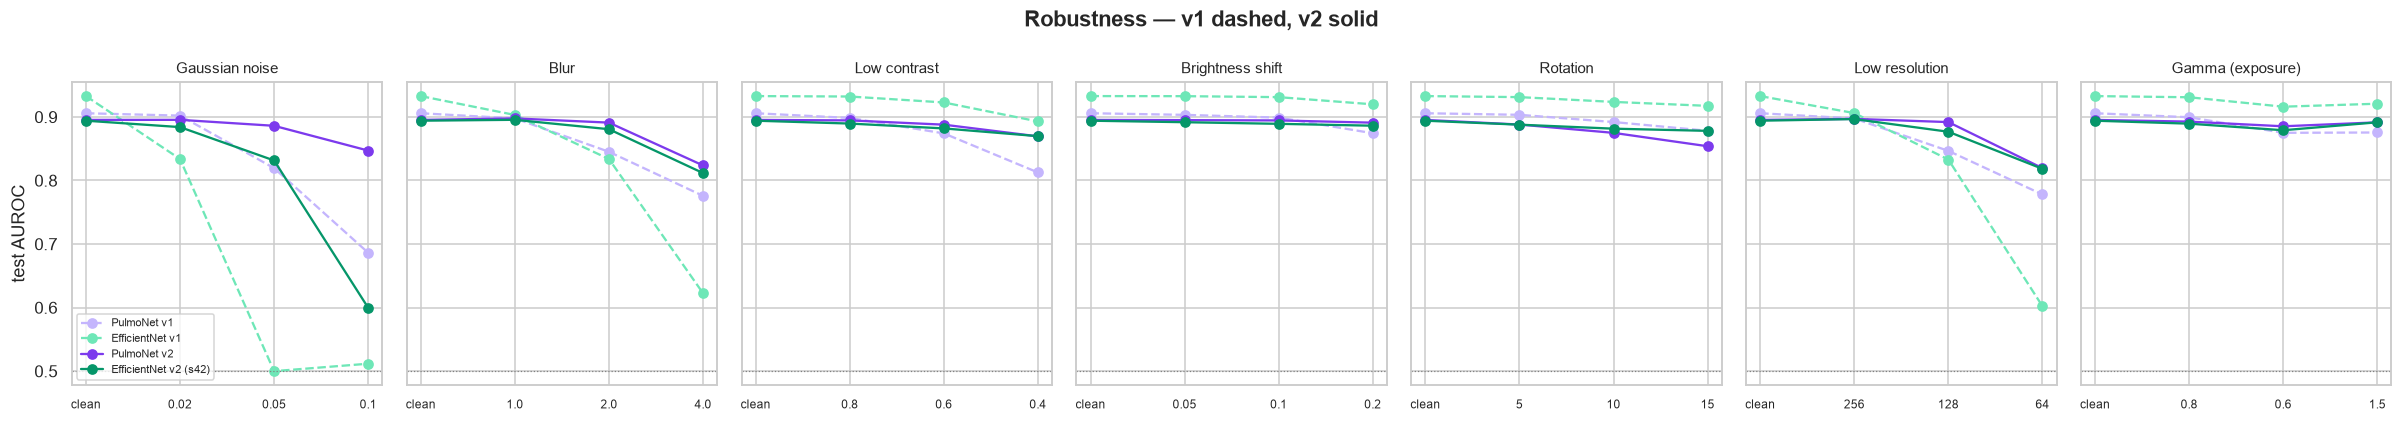

In [11]:
STY = {"PulmoNet v1": ("#C4B5FD", "--"), "EfficientNet v1": ("#6EE7B7", "--"), "PulmoNet v2": ("#7C3AED", "-"), "EfficientNet v2 (s42)": ("#059669", "-")}
fig, axes = plt.subplots(1, len(CORR), figsize=(22, 3.9), sharey=True)
for ax, c in zip(axes, CORR):
    for n in ROB_MODELS:
        d = rob[(rob.model == n) & ((rob.corruption == c) | (rob.corruption == "clean"))].sort_values("level")
        ax.plot(d.level, d.AUROC, "o", ls=STY[n][1], color=STY[n][0], label=n)
    ax.set_xticks([0, 1, 2, 3], ["clean"] + [str(s) for s in CORR[c][1]], fontsize=8); ax.set_title(c, fontsize=10)
    ax.axhline(0.5, color="gray", ls=":", lw=0.8)
axes[0].set_ylabel("test AUROC"); axes[0].legend(fontsize=7, loc="lower left")
plt.suptitle("Robustness — v1 dashed, v2 solid", weight="bold"); plt.tight_layout()
plt.savefig(ROOT / "results" / "comparison" / "v2_robustness.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Shortcut check with real lung masks

In [12]:
def load_masks(df, col):
    with ThreadPoolExecutor(12) as pool:
        ms = list(pool.map(lambda p: tvio.decode_image(tvio.read_file(str(ROOT / p)), mode=tvio.ImageReadMode.GRAY), df[col]))
    return torch.stack(ms) > 127          # bool on CPU (1 byte/pixel); moved to the GPU per batch

test_full = frame("full", "test"); test_crop = frame("crop", "test")
MASK = {"full": load_masks(test_crop, "mask_path"), "crop": load_masks(test_crop, "crop_mask_path")}

def occlude(kind, keep):
    def fn(x, g, kind=kind):
        idx = fn.i; m = MASK[kind][idx:idx + x.size(0)].to(x.device, x.dtype); fn.i += x.size(0)
        fill = x.mean((2, 3), keepdim=True)
        return x * m + fill * (1 - m) if keep == "lungs" else x * (1 - m) + fill * m
    fn.i = 0
    return fn

occl = {}
for n in ROB_MODELS:
    k = INPUT[n]
    occl[n] = {"original": roc_auc_score(Y["test"], test_probs(models_[n], k)),
               "lungs hidden": roc_auc_score(Y["test"], test_probs(models_[n], k, occlude(k, "outside"))),
               "only lungs visible": roc_auc_score(Y["test"], test_probs(models_[n], k, occlude(k, "lungs")))}
occl = pd.DataFrame(occl)
display(occl.style.format("{:.3f}"))

,PulmoNet v1,EfficientNet v1,PulmoNet v2,EfficientNet v2 (s42)
original,0.906,0.933,0.895,0.894
lungs hidden,0.747,0.856,0.737,0.779
only lungs visible,0.747,0.838,0.818,0.835


In [13]:
def grad_cam(model, layer, x):
    store = {}
    def fwd(_m, _i, out):
        store["act"] = out; out.register_hook(lambda g_: store.__setitem__("grad", g_))
    h = layer.register_forward_hook(fwd)
    try:
        model.zero_grad(set_to_none=True); model(x)[:, 1].sum().backward()
        w = store["grad"].float().mean((2, 3), keepdim=True)
        cam = (w * store["act"].float()).sum(1, keepdim=True).relu()
        return F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).detach()
    finally:
        h.remove()

layer_of = lambda n: models_[n].head_conv if n.startswith("PulmoNet") else models_[n].features[-1]
tb_idx = np.where(Y["test"] == 1)[0][:400]
cam_in, area = {}, {}
for n in ROB_MODELS:
    k, fr = INPUT[n], []
    for i in range(0, len(tb_idx), 16):
        idx = tb_idx[i:i + 16]
        x = ((TEST_U8[k][idx].to(DEVICE).float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        cam = grad_cam(models_[n], layer_of(n), x); m = MASK[k][idx].to(DEVICE).float()
        fr.append(((cam * m).sum((1, 2, 3)) / (cam.sum((1, 2, 3)) + 1e-8)).cpu())
    cam_in[n] = torch.cat(fr).numpy(); area[n] = MASK[k][tb_idx].float().mean().item()
lung_focus = pd.DataFrame({"median Grad-CAM heat inside lungs": {n: np.median(v) for n, v in cam_in.items()},
                           "lung share of image (random baseline)": area})
lung_focus["focus ratio (heat share / area share)"] = lung_focus.iloc[:, 0] / lung_focus.iloc[:, 1]
display(lung_focus.style.format("{:.2f}"))

,median Grad-CAM heat inside lungs,lung share of image (random baseline),focus ratio (heat share / area share)
PulmoNet v1,0.38,0.34,1.13
EfficientNet v1,0.46,0.34,1.38
PulmoNet v2,0.58,0.42,1.38
EfficientNet v2 (s42),0.50,0.42,1.20


### Where do v1 and v2 look? Same test X-rays, Grad-CAM side by side

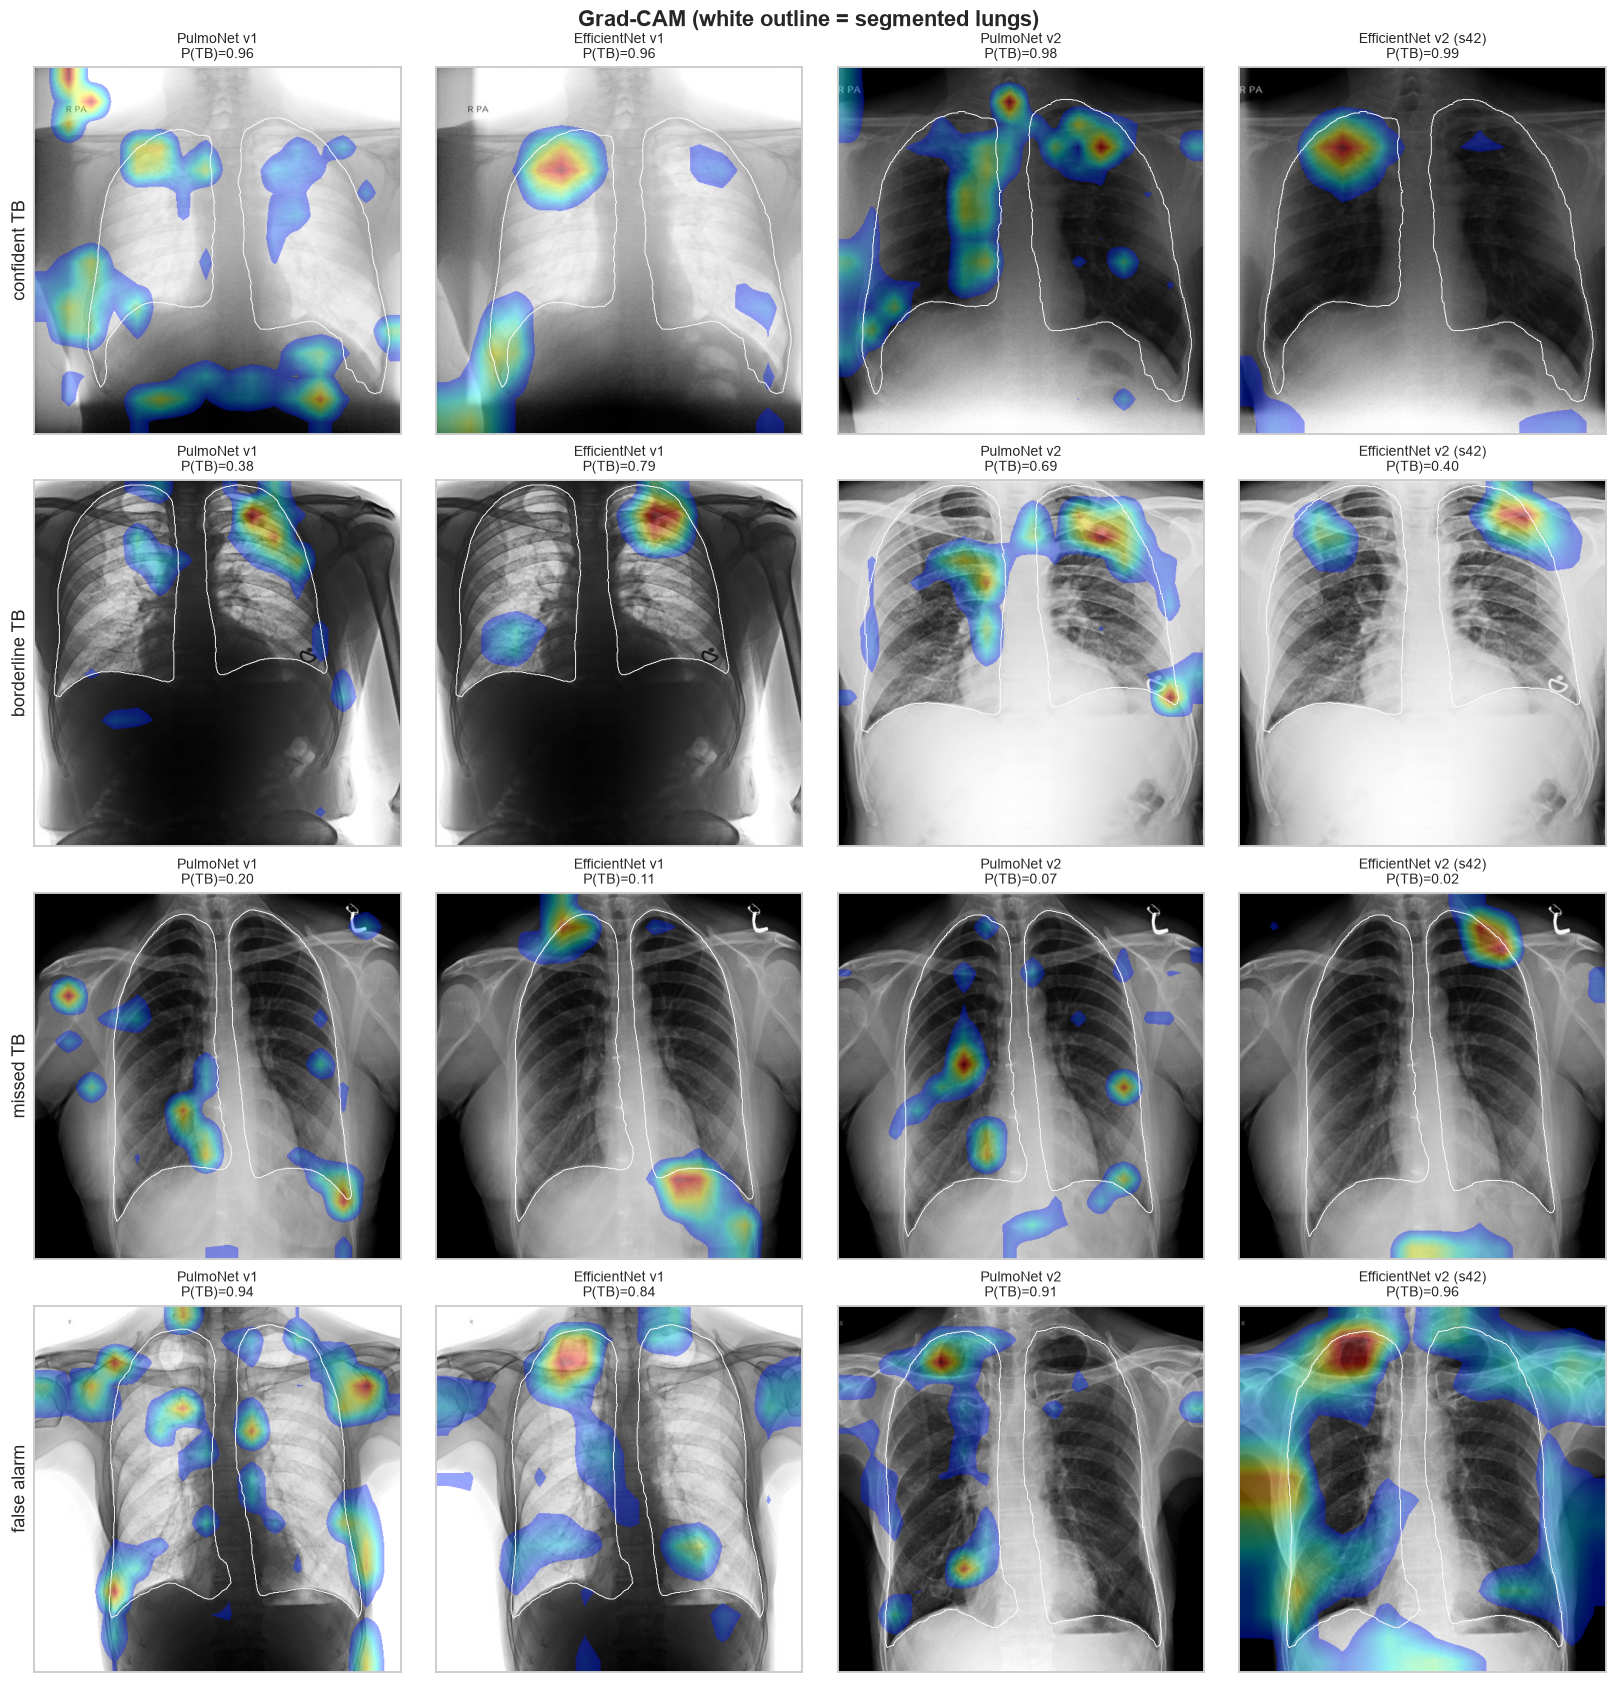

In [14]:
pe = P[ens]["test"]
pick = {"confident TB": np.argmax(np.where(Y["test"] == 1, pe, -1)),
        "borderline TB": np.argmin(np.where(Y["test"] == 1, np.abs(pe - TH[ens]["balanced"]), 9)),
        "missed TB": np.argmin(np.where((Y["test"] == 1) & (pe < TH[ens]["balanced"]), pe, 9)),
        "false alarm": np.argmax(np.where((Y["test"] == 0) & (pe >= TH[ens]["balanced"]), pe, -1))}
fig, axes = plt.subplots(len(pick), 4, figsize=(15, 3.9 * len(pick)))
for r, (case, i) in enumerate(pick.items()):
    for c, n in enumerate(ROB_MODELS):
        k = INPUT[n]; raw = TEST_U8[k][i:i + 1].to(DEVICE)
        cam = grad_cam(models_[n], layer_of(n), ((raw.float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last))[0, 0].cpu().numpy()
        cam = cam / (cam.max() + 1e-8)
        axes[r, c].imshow(raw[0, 0].cpu(), cmap="gray"); axes[r, c].imshow(cam, cmap="jet", alpha=0.4 * (cam > 0.15))
        axes[r, c].contour(MASK[k][i, 0].float().numpy(), levels=[0.5], colors="white", linewidths=0.6)
        axes[r, c].set_title(f"{n}\nP(TB)={P[n]['test'][i]:.2f}", fontsize=9)
    axes[r, 0].set_ylabel(case)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Grad-CAM (white outline = segmented lungs)", weight="bold"); plt.tight_layout()
plt.savefig(ROOT / "results" / "comparison" / "v2_gradcam.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Selective prediction and seed stability

In [15]:
def acc_at_coverage(y, p, t, c):
    order = np.argsort(-np.abs(p - t)); k = int(c * len(y))
    return float(((p[order[:k]] >= t) == y[order[:k]]).mean())
sel = pd.DataFrame({n: {f"{int(c * 100)}% coverage": acc_at_coverage(Y["test"], P[n]["test"], TH[n]["balanced"], c) for c in [1.0, 0.9, 0.8, 0.7]} for n in NAMES}).T
display(sel.style.format("{:.3f}"))
seed_auc = [roc_auc_score(Y["test"], P[n]["test"]) for n in seed_names]
print(f"EfficientNet v2 test AUROC across seeds: {np.round(seed_auc, 4)} -> mean {np.mean(seed_auc):.4f}, std {np.std(seed_auc, ddof=1):.4f}")

,100% coverage,90% coverage,80% coverage,70% coverage
PulmoNet v1,0.835,0.861,0.871,0.870
EfficientNet v1,0.854,0.893,0.923,0.943
PulmoNet v2,0.816,0.853,0.877,0.897
EfficientNet v2 (s42),0.816,0.851,0.878,0.894
EfficientNet v2 (s7),0.818,0.847,0.873,0.895
EfficientNet v2 (s2024),0.820,0.850,0.875,0.895
EfficientNet v2 ensemble,0.819,0.853,0.878,0.900


EfficientNet v2 test AUROC across seeds: [0.8941 0.8918 0.8947] -> mean 0.8935, std 0.0016


## 8. Significance tests (DeLong, paired AUROC)

In [16]:
from scipy.stats import norm
def _midrank(x):
    o = np.argsort(x); z = x[o]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]: j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(n); out[o] = t; return out
def delong(y, p1, p2):
    o = np.argsort(-y, kind="stable"); m = int(y.sum()); n = len(y) - m
    pr = np.vstack([p1, p2])[:, o]
    tx = np.array([_midrank(r[:m]) for r in pr]); ty = np.array([_midrank(r[m:]) for r in pr]); tz = np.array([_midrank(r) for r in pr])
    a = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    return a[0] - a[1], 2 * norm.sf(abs(a[0] - a[1]) / np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1]))
pairs = [("PulmoNet v2", "PulmoNet v1"), ("EfficientNet v2 (s42)", "EfficientNet v1"), (ens, "EfficientNet v1"),
         (ens, "PulmoNet v2"), ("EfficientNet v2 (s42)", "PulmoNet v2")]
display(pd.DataFrame([{"comparison": f"{a}  vs  {b}", "ΔAUROC": d, "DeLong p": p} for a, b in pairs for d, p in [delong(Y["test"], P[a]["test"], P[b]["test"])]])
        .style.format({"ΔAUROC": "{:+.4f}", "DeLong p": "{:.2g}"}))

,comparison,ΔAUROC,DeLong p
0,PulmoNet v2 vs PulmoNet v1,-0.0105,0.052
1,EfficientNet v2 (s42) vs EfficientNet v1,-0.0387,1.4e-11
2,EfficientNet v2 ensemble vs EfficientNet v1,-0.0374,4.5e-11
3,EfficientNet v2 ensemble vs PulmoNet v2,+0.0001,0.98
4,EfficientNet v2 (s42) vs PulmoNet v2,-0.0012,0.8


## 9. Pass / fail against the targets fixed before training

In [17]:
def rob_at(n, c, lvl): return rob[(rob.model == n) & (rob.corruption == c) & (rob.level == lvl)].AUROC.iloc[0]
def targets(n, ref):
    r = {"Test AUROC": (ov.loc[n, "test AUROC"], ">=", 0.93 if "Efficient" in n else 0.91),
         "Clean train AUROC (not underfit)": (ov.loc[n, "train AUROC (clean)"], ">=", 0.95),
         "Train − test AUROC (not overfit)": (ov.loc[n, "train−test AUROC"], "<=", 0.03),
         "|Val − test AUROC|": (abs(ov.loc[n, "val−test AUROC"]), "<=", 0.015),
         "Brier (calibrated)": (RES[("balanced", n)]["Brier"][0], "<=", 0.10),
         "Accuracy @ 80% coverage": (sel.loc[n, "80% coverage"], ">=", 0.93)}
    if ref in ROB_MODELS:
        r.update({"AUROC, noise σ=0.05": (rob_at(ref, "Gaussian noise", 2), ">=", 0.88),
                  "AUROC, blur σ=4": (rob_at(ref, "Blur", 3), ">=", 0.80),
                  "AUROC, 64 px": (rob_at(ref, "Low resolution", 3), ">=", 0.80),
                  "AUROC, lungs hidden": (occl.loc["lungs hidden", ref], "<=", 0.65),
                  "Grad-CAM focus ratio": (lung_focus.loc[ref].iloc[2], ">=", 1.3)})
    return r
rows = []
for n, ref in [("PulmoNet v2", "PulmoNet v2"), ("EfficientNet v2 (s42)", "EfficientNet v2 (s42)"), (ens, "EfficientNet v2 (s42)")]:
    for crit, (v, op, t) in targets(n, ref).items():
        ok = v >= t if op == ">=" else v <= t
        rows.append({"model": n, "criterion": crit, "value": round(float(v), 4), "target": f"{op} {t}", "pass": "PASS" if ok else "FAIL"})
verdict = pd.DataFrame(rows)
display(verdict.pivot(index="criterion", columns="model", values="value").join(
        verdict.pivot(index="criterion", columns="model", values="pass"), rsuffix=" ✓"))
print(verdict.groupby("model")["pass"].apply(lambda s: f"{(s == 'PASS').sum()}/{len(s)} targets met"))

model,EfficientNet v2 (s42),EfficientNet v2 ensemble,PulmoNet v2,EfficientNet v2 (s42) ✓,EfficientNet v2 ensemble ✓,PulmoNet v2 ✓
criterion,,,,,,
"AUROC, 64 px",0.8184,0.8184,0.8194,PASS,PASS,PASS
"AUROC, blur σ=4",0.8117,0.8117,0.8237,PASS,PASS,PASS
"AUROC, lungs hidden",0.7792,0.7792,0.7369,FAIL,FAIL,FAIL
"AUROC, noise σ=0.05",0.8315,0.8315,0.8861,FAIL,FAIL,PASS
Accuracy @ 80% coverage,0.8780,0.8780,0.8772,FAIL,FAIL,FAIL
Brier (calibrated),0.1331,0.1314,0.1289,FAIL,FAIL,FAIL
Clean train AUROC (not underfit),0.9354,0.9370,0.9533,FAIL,FAIL,PASS
Grad-CAM focus ratio,1.1957,1.1957,1.3780,FAIL,FAIL,PASS
Test AUROC,0.8941,0.8954,0.8953,FAIL,FAIL,FAIL


model
EfficientNet v2 (s42)       3/11 targets met
EfficientNet v2 ensemble    2/11 targets met
PulmoNet v2                 6/11 targets met
Name: pass, dtype: str


## 10. Export results

In [18]:
def pts(x, y, k=150):
    i = np.unique(np.linspace(0, len(x) - 1, k).astype(int)); return [[round(float(x[j]), 4), round(float(y[j]), 4)] for j in i]
exp = {"test_size": int(len(Y["test"])), "models": {}}
for n in NAMES:
    fpr, tpr, _ = roc_curve(Y["test"], P[n]["test"])
    exp["models"][n] = {"input": INPUT[n], "temperature": T[n], "thresholds": TH[n], "roc": pts(fpr, tpr),
                        "metrics": {op: {k: [round(float(v), 4) for v in vals] for k, vals in RES[(op, n)].items()} for op in ["balanced", "screening"]},
                        "overfitting": ov.loc[n].round(4).to_dict(), "selective": sel.loc[n].round(4).to_dict()}
exp["robustness"] = rob.round(4).to_dict("records"); exp["occlusion"] = occl.round(4).to_dict()
exp["lung_focus"] = lung_focus.round(4).to_dict(); exp["targets"] = verdict.to_dict("records")
(ROOT / "results" / "comparison" / "comparison_v2.json").write_text(json.dumps(exp, indent=2, default=float))
print("Saved results/comparison/comparison_v2.json")

Saved results/comparison/comparison_v2.json
